# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [2]:
#Please write the code here
%pip install seaborn scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

dataset = pd.read_csv('car_purchase_data.csv')
dataset.info()

Note: you may need to restart the kernel to use updated packages.
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   User ID    400 non-null    int64
 1   Gender     400 non-null    str  
 2   Age        400 non-null    int64
 3   Salary     400 non-null    int64
 4   Purchased  400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


### Step 2: Split features and target

In [3]:
#Please write the code here

X = dataset[['Age', 'Salary']]
Y = dataset['Purchased']

### Step 3: Train/Test Split

In [4]:
#Please write the code here

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=0)
print(X_train.shape, X_test.shape)

(300, 2) (100, 2)


### Step 4: Feature Scaling

In [5]:
#Please write the code here

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Step 5: Train Logistic Regression Model

In [6]:
#Please write the code here

from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(random_state=0)
classifier.fit(X_train, Y_train)
print('Coefficients:', classifier.coef_)
print('Intercept:', classifier.intercept_)

Coefficients: [[2.07665837 1.11008221]]
Intercept: [-0.95217247]


### Step 6: Predict and Evaluate

Accuracy: 0.89
[[65  3]
 [ 8 24]]
              precision    recall  f1-score   support

           0       0.89      0.96      0.92        68
           1       0.89      0.75      0.81        32

    accuracy                           0.89       100
   macro avg       0.89      0.85      0.87       100
weighted avg       0.89      0.89      0.89       100



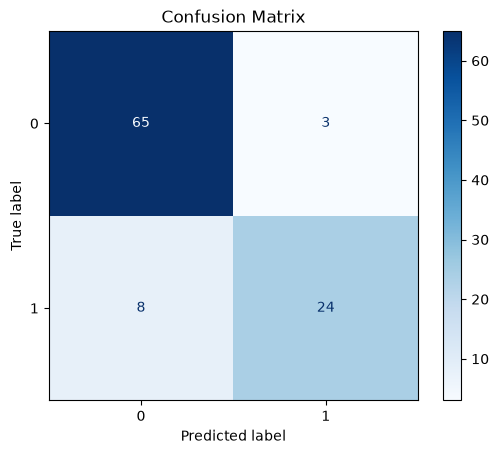

In [7]:
#Please write the code here

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

Y_pred = classifier.predict(X_test)

print('Accuracy:', accuracy_score(Y_test, Y_pred))
print(confusion_matrix(Y_test, Y_pred))
print(classification_report(Y_test, Y_pred))

ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred, cmap='Blues')
plt.title('Confusion Matrix')
plt.show()


In [8]:
Y_prob = classifier.predict_proba(X_test)[:, 1]
print(Y_prob[:10])
print(Y_pred[:10]) #If the probability is 0.5 or higher, the model predicts 1 (buys).

[0.11275338 0.16679594 0.19452734 0.08944762 0.09748596 0.00787412
 0.01514882 0.73214818 0.00581025 0.50427605]
[0 0 0 0 0 0 0 1 0 1]


### Step 7: Visualization of Decision Regions

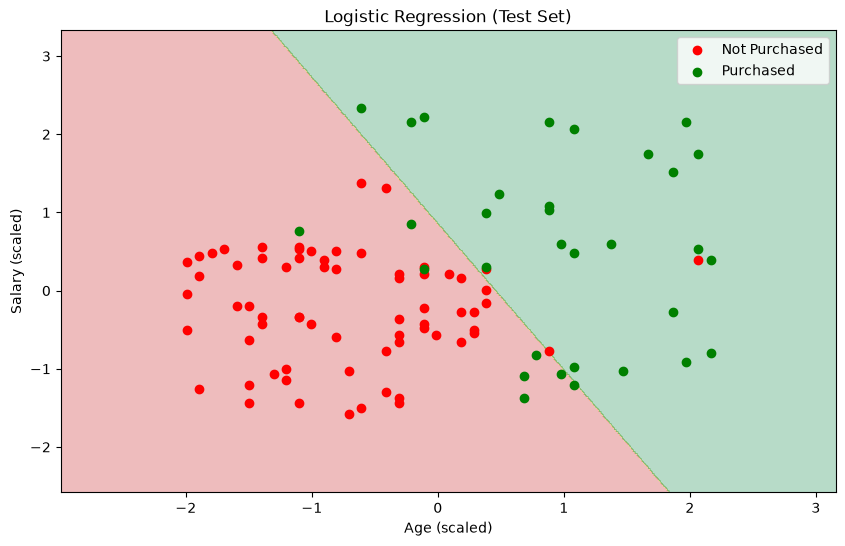

In [9]:
#Please write the code here

X_set, Y_set = X_test, Y_test.values

# Make a grid of points covering the whole plot
x1, x2 = np.meshgrid(np.arange(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, 0.01),
                     np.arange(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, 0.01))

# Predict every point on the grid
Z = classifier.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)

plt.figure(figsize=(10,6))
plt.contourf(x1, x2, Z, alpha=0.3, cmap='RdYlGn')
plt.scatter(X_set[Y_set == 0, 0], X_set[Y_set == 0, 1], color='r', label='Not Purchased')
plt.scatter(X_set[Y_set == 1, 0], X_set[Y_set == 1, 1], color='g', label='Purchased')
plt.title('Logistic Regression (Test Set)')
plt.xlabel('Age (scaled)')
plt.ylabel('Salary (scaled)')
plt.legend()
plt.show()

## IV. Reflection Questions 
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1. Logistic regression uses the sigmoid function to output a probability between 0 and 1, and a threshold (usually 0.5) turns that probability into a class. If the probability of purchasing is 0.5 or higher, the customer is predicted as 1 (buys); otherwise, 0.

2. Older customers with higher salaries are the most likely to purchase, with age having a stronger effect than salary. The decision region plot shows buyers concentrated in the upper-right, while younger, lower-income customers fall in the “not purchased” region.

3. My model reached 89% accuracy but missed 8 of the 32 actual buyers, partly because it only uses two features and its straight-line boundary can’t capture curved patterns. The plot also shows overlapping points near the boundary, and there are about twice as many non-buyers (68) as buyers (32), which makes the model lean toward predicting “not purchased.”

4. Adding features like gender, number of children, or existing car ownership would give the model more information to separate buyers from non-buyers. Balancing the classes with class_weight='balanced', adding an Age × Salary interaction feature, and tuning the regularization parameter could also reduce the missed buyers.